# Session 8: error analysis

Loads the saved tables in `artifacts/session8/` and reproduces the key tables and figures. No model is loaded or run, no file is written and the FD003 label file is not read. Run top to bottom from anywhere inside the project.

Two aggregations are used: plain `rmse`/`mae`/`median_abs` are **pooled** over predictions; `engine_mean_*` are computed per engine and then averaged (empty where one prediction per engine makes them meaningless).

## 1. Setup

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/session8_evaluation.yaml").exists())
A = ROOT / "artifacts/session8"
manifest = json.loads((A / "manifest.json").read_text())

def load(name):
    return pd.read_csv(A / f"{name}.csv")

SETS = ["fd001_validation", "fd003_train", "fd003_test"]
MODELS = ["random_forest", "gradient_boosting", "lstm", "gru", "tcn", "transformer"]
FULL = ["rf_full", "gb_full", "lstm_full", "gru_full", "tcn_full", "transformer_full"]
STAGES = ["near_failure", "intermediate", "early_life"]

## 2. Check the tables against the manifest

In [2]:
import hashlib
changed = [n for n, d in manifest["files"].items() if hashlib.sha256((A / n).read_bytes()).hexdigest() != d]
assert not changed, changed
master = load("master_results")
assert len(master) == 174 and master["experiment_id"].is_unique
print(manifest["evidence_class"], "| canonical:", manifest["canonical"])

not canonical: the source state of some evidence was not recorded | canonical: False


## 3. Transfer from FD001 to FD003

The three sets are different protocols; FD001 validation is selection-affected.

dataset           fd001_validation  fd003_train  fd003_test
candidate                                                  
gb_full                      12.79        17.60       20.98
gb_k10_random                13.40        18.57       21.42
gru_full                     12.44        22.23       27.52
gru_k02_corr                 18.95        17.84       19.99
gru_k02_perm                 17.32        17.07       18.05
gru_k10_perm                 12.56        23.99       29.59
lstm_full                    12.99        19.68       23.41
rf_full                      12.95        18.06       20.02
tcn_full                     14.64        89.87      116.53
tcn_k07_perm                 14.82        21.86       23.02
transformer_full             12.32        23.78       30.95


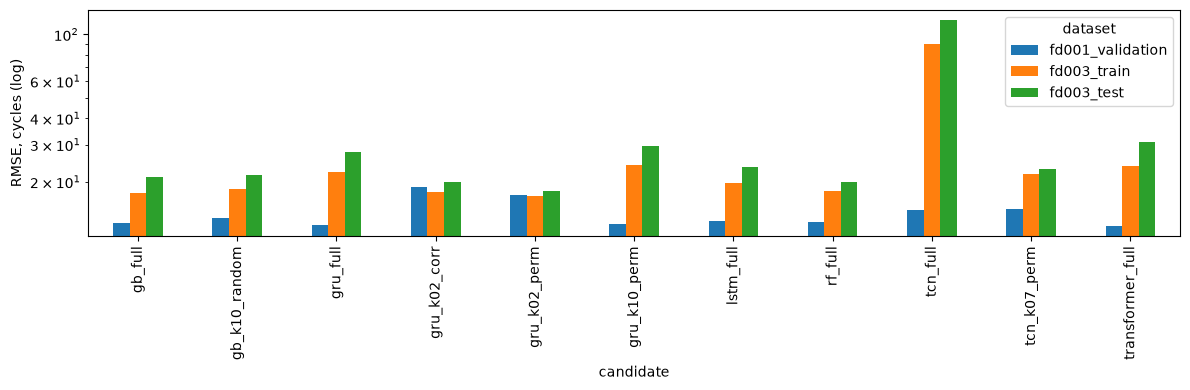

In [3]:
summary = load("candidate_summary")
table = summary.pivot(index="candidate", columns="dataset", values="rmse")[SETS]
print(table.round(2).to_string())
ax = table.plot.bar(figsize=(12, 4), logy=True)
ax.set_ylabel("RMSE, cycles (log)")
plt.tight_layout(); plt.show()

## 4. Error by RUL stage

One value per engine, averaged over engines.

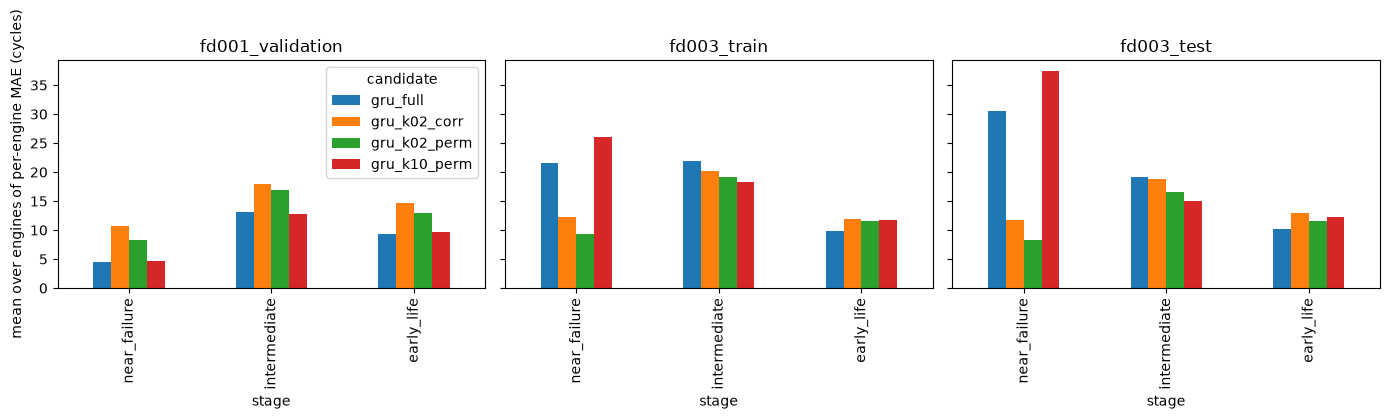

    candidate reference          dataset        stage  n_engines  full_mae  reduced_mae  mae_change  mae_change_pct  ci95_low  ci95_high  engines_worse  engines_better
 gru_k10_perm  gru_full fd001_validation near_failure         20      4.49         4.75        0.27            5.94     -0.16       0.71             10              10
 gru_k10_perm  gru_full fd001_validation intermediate         20     13.18        12.76       -0.42           -3.19     -1.09       0.26              7              13
 gru_k10_perm  gru_full fd001_validation   early_life         20      9.26         9.69        0.43            4.69     -0.33       1.12             13               7
 gru_k10_perm  gru_full      fd003_train near_failure        100     21.54        26.03        4.49           20.86      3.19       5.84             67              33
 gru_k10_perm  gru_full      fd003_train intermediate        100     21.97        18.21       -3.76          -17.09     -5.07      -2.51             35         

In [4]:
stage = load("stage_metrics")
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, dataset in zip(axes, SETS):
    part = stage[(stage.dataset == dataset) & stage.candidate.isin(["gru_full", "gru_k10_perm", "gru_k02_perm", "gru_k02_corr"])]
    part.pivot(index="stage", columns="candidate", values="engine_mean_mae").loc[STAGES].plot.bar(ax=ax, legend=dataset == SETS[0])
    ax.set_title(dataset)
axes[0].set_ylabel("mean over engines of per-engine MAE (cycles)")
plt.tight_layout(); plt.show()
print(load("stage_full_vs_reduced").round(2).to_string(index=False))

## 5. Late versus early predictions

error = predicted - true; positive is optimistic.

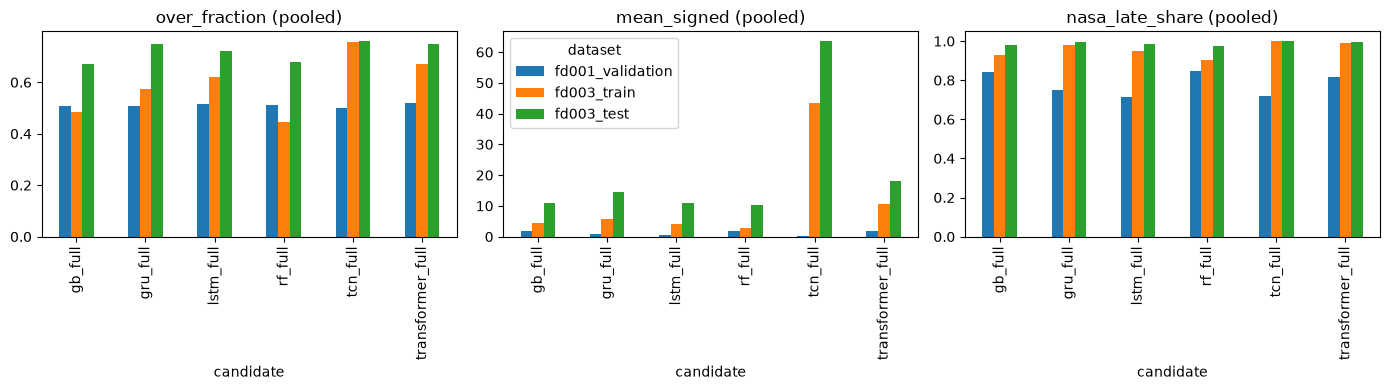

       candidate          dataset  engine_mean_over_fraction  engine_mean_signed
transformer_full fd001_validation                       0.55                2.84
transformer_full      fd003_train                       0.66               10.55
transformer_full       fd003_test                       0.75               17.99
        gru_full fd001_validation                       0.54                1.66
        gru_full      fd003_train                       0.60                6.78
        gru_full       fd003_test                       0.75               14.58
         gb_full fd001_validation                       0.55                2.70
         gb_full      fd003_train                       0.53                5.70
         gb_full       fd003_test                       0.67               11.05
         rf_full fd001_validation                       0.55                2.84
         rf_full      fd003_train                       0.51                4.53
         rf_full       fd003

In [5]:
asym = load("asymmetry")
part = asym[asym.candidate.isin(FULL)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column in zip(axes, ["over_fraction", "mean_signed", "nasa_late_share"]):
    part.pivot(index="candidate", columns="dataset", values=column)[SETS].plot.bar(ax=ax, legend=column == "mean_signed")
    ax.set_title(f"{column} (pooled)")
plt.tight_layout(); plt.show()

print(part[["candidate", "dataset", "engine_mean_over_fraction", "engine_mean_signed"]].round(2).to_string(index=False))

## 6. Worst engines and agreement between architectures

`all_full_models` is the predeclared rule; `without_tcn` was added after the results were seen, because the failed TCN dominates a pooled score.

dataset           view             criterion     
fd001_validation  all_full_models  absolute_error    [57, 28, 93, 100, 98]
                                   late_error         [57, 28, 93, 98, 60]
                                   early_error        [22, 5, 100, 26, 52]
                                   near_failure       [57, 93, 43, 28, 98]
                  without_tcn      absolute_error    [57, 28, 93, 100, 98]
                                   late_error         [57, 28, 98, 93, 60]
                                   early_error        [22, 5, 100, 26, 52]
                                   near_failure       [57, 28, 43, 93, 98]
fd003_train       all_full_models  absolute_error     [42, 60, 73, 11, 46]
                                   late_error         [60, 42, 46, 11, 89]
                                   early_error           [4, 8, 15, 86, 6]
                                   near_failure       [42, 89, 11, 60, 73]
                  without_tcn      absolute_error 

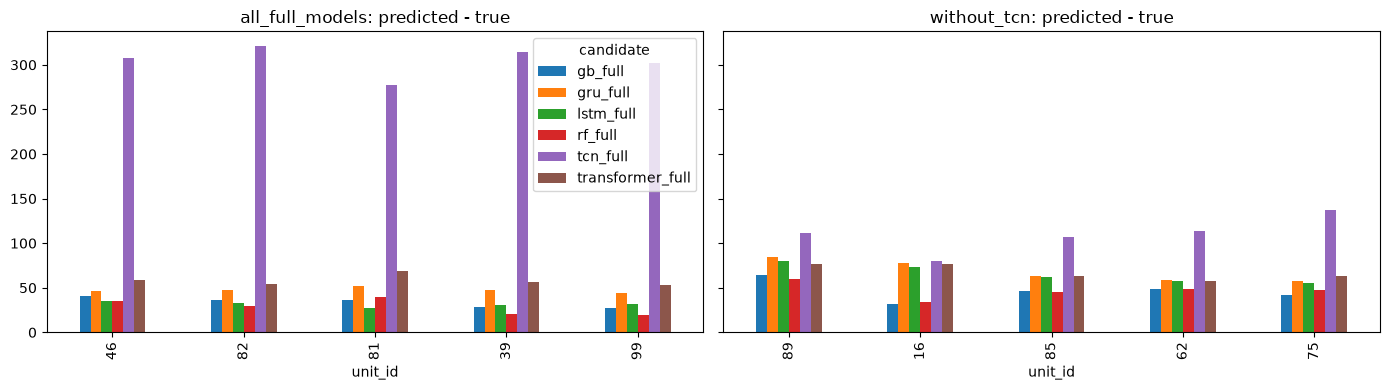

In [6]:
worst = load("worst_engines")
print(worst.groupby(["dataset", "view", "criterion"], sort=False)["unit_id"].apply(list).to_string())
print(load("family_agreement").groupby("dataset")[["spearman_rho", "shared_worst"]].describe().T.round(2).to_string())

engines = load("per_engine_candidates")
shown = worst[(worst.dataset == "fd003_test") & (worst.criterion == "absolute_error")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (view, part) in zip(axes, shown.groupby("view", sort=False)):
    picked = engines[(engines.dataset == "fd003_test") & engines.unit_id.isin(part.unit_id) & engines.candidate.isin(FULL)]
    picked.pivot(index="unit_id", columns="candidate", values="mean_signed").loc[list(part.unit_id)].plot.bar(ax=ax, legend=view == "all_full_models")
    ax.set_title(f"{view}: predicted - true")
plt.tight_layout(); plt.show()

## 7. Declared paired tests (FD003 test)

In [7]:
tests = load("statistics")
print(tests[tests.family != "C_ranked_vs_random_mean"][["family", "a", "b", "median_difference", "p_holm", "significant_after_correction"]].to_string(index=False))
c = tests[tests.family == "C_ranked_vs_random_mean"]
lower = c.significant_after_correction & (c.median_difference < 0)
higher = c.significant_after_correction & (c.median_difference > 0)
print(pd.DataFrame({"significantly_lower": lower.groupby(c.strategy).sum(), "significantly_higher": higher.groupby(c.strategy).sum()}))

print(load("architecture_order").query("kind == 'spearman'")[["protocol", "value"]].to_string(index=False))

             family             a                b  median_difference       p_holm  significant_after_correction
  A_reduced_vs_full  gru_k10_perm         gru_full           0.557385 6.110843e-01                         False
  A_reduced_vs_full  tcn_k07_perm         tcn_full          -6.580312 7.490214e-09                          True
  A_reduced_vs_full gb_k10_random          gb_full           0.310046 6.110843e-01                         False
  A_reduced_vs_full  gru_k02_perm         gru_full          -2.174312 7.101637e-03                          True
  A_reduced_vs_full  gru_k02_corr         gru_full          -0.676051 4.015356e-01                         False
B_full_vs_reference      gru_full transformer_full          -1.664139 6.953041e-03                          True
B_full_vs_reference       gb_full transformer_full          -2.987629 4.813234e-05                          True
B_full_vs_reference       rf_full transformer_full          -3.443301 4.813234e-05              

## 8. Sensitivity: ranking method and training cap

fd001_val {'correlation': 2, 'permutation': 24}
fd003_train {'correlation': 11, 'permutation': 20}
fd003_test {'correlation': 11, 'permutation': 19}


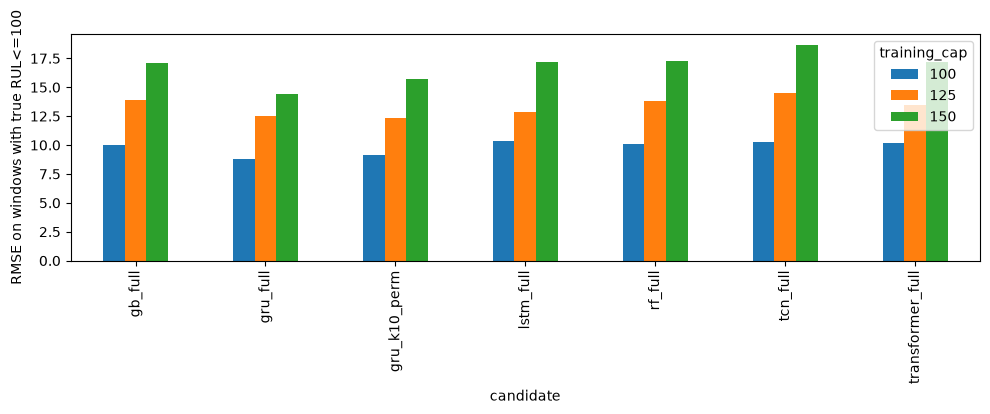

In [8]:
rank = load("sensitivity_ranking")
for d in ["fd001_val", "fd003_train", "fd003_test"]:
    print(d, rank.assign(below=rank[f"{d}_ranked_rmse"] < rank[f"{d}_random_mean_rmse"]).groupby("strategy")["below"].sum().to_dict())
caps = load("sensitivity_cap")
ax = caps.pivot(index="candidate", columns="training_cap", values="common_subset_rmse").plot.bar(figsize=(10, 4))
ax.set_ylabel("RMSE on windows with true RUL<=100"); plt.tight_layout(); plt.show()

## 9. Input shift and sensor exposure (exploratory)

In [9]:
shift = load("input_shift")
print(shift[shift.used_by_models].round(3).to_string(index=False))
exposure = load("exploratory_sensor_exposure")
print(exposure[exposure.sensor.isin(["sensor_7", "sensor_12"])].round(1).to_string(index=False))

   sensor  used_by_models  fd003_test_windows_mean_in_fd001_sd  fd003_test_windows_sd_in_fd001_sd  fd003_test_windows_fraction_beyond_3_sd  fd003_mean_in_fd001_sd  fd003_sd_in_fd001_sd  fraction_beyond_3_sd  fd001_raw_sd  fd003_raw_sd
 sensor_2            True                               -0.353                              0.884                                    0.000                  -0.447                 1.046                 0.002         0.500         0.523
 sensor_3            True                               -0.267                              0.949                                    0.001                  -0.400                 1.113                 0.005         6.131         6.810
 sensor_4            True                               -0.399                              0.900                                    0.000                  -0.499                 1.087                 0.001         9.000         9.773
 sensor_7            True                                2.4

## 10. Efficiency

Latency is the single Session 7 measurement and is coarse.

In [10]:
full = master[master.strategy == "full"].set_index("model").loc[MODELS]
print(full[["fd001_validation_rmse", "fd003_test_rmse", "inference_latency_ms_per_batch", "n_parameters", "model_size_bytes", "train_time_s"]].round(2).to_string())

                   fd001_validation_rmse  fd003_test_rmse  inference_latency_ms_per_batch  n_parameters  model_size_bytes  train_time_s
model                                                                                                                                  
random_forest                      12.95            20.02                            4.32        117656           8505496          1.64
gradient_boosting                  12.79            20.98                            3.51         12196            875517          0.90
lstm                               12.99            23.41                            5.02         14625             63262         13.19
gru                                12.44            27.52                            3.09         15425             65645         20.07
tcn                                14.64           116.53                           48.47         23617            101674        152.89
transformer                        12.32        